# 01 - Data Acquisition and Exploratory Analysis

**Dry Bean Variety Classification** - UCI dataset 602.

This notebook downloads (if needed) and validates the official workbook, then
reproduces the figures used in Chapter 3. All plotting code lives in
`src/eda.py`; the notebook calls it so the report and the notebook cannot drift
apart.

In [1]:
import os, sys, pathlib
root = pathlib.Path.cwd()
while not (root / "src" / "config.py").exists():
    root = root.parent
sys.path.insert(0, str(root))
os.chdir(root)          # relative paths in the notebooks resolve from the root
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
pd.set_option("display.width", 160)
print("project root:", root)

project root: /home/shreyas/projects/dry-bean-classification


## 1. Load and validate

In [2]:
from src.data_loader import load_dataset, validate
df = load_dataset()
print(df.shape)
df.head()

(13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [3]:
report = validate(df)
{k: report[k] for k in ["rows", "columns", "feature_count", "missing_values_total",
                        "duplicate_rows", "class_imbalance_ratio"]}

{'rows': 13611,
 'columns': 17,
 'feature_count': 16,
 'missing_values_total': 0,
 'duplicate_rows': 68,
 'class_imbalance_ratio': 6.79}

In [4]:
report["class_counts_ordered"]

{'SEKER': 2027,
 'BARBUNYA': 1322,
 'BOMBAY': 522,
 'CALI': 1630,
 'DERMASON': 3546,
 'HOROZ': 1928,
 'SIRA': 2636}

In [5]:
report["feature_pairs_abs_corr_ge_0.90"]

{'Area ~ ConvexArea': 0.9999,
 'Compactness ~ ShapeFactor3': 0.9987,
 'Perimeter ~ EquivDiameter': 0.9914,
 'AspectRation ~ Compactness': -0.9877,
 'ConvexArea ~ EquivDiameter': 0.9852,
 'Area ~ EquivDiameter': 0.985,
 'Eccentricity ~ ShapeFactor3': -0.9811,
 'AspectRation ~ ShapeFactor3': -0.9786,
 'Perimeter ~ MajorAxisLength': 0.9773,
 'Eccentricity ~ Compactness': -0.9703,
 'Perimeter ~ ConvexArea': 0.9677,
 'Area ~ Perimeter': 0.9667,
 'MajorAxisLength ~ EquivDiameter': 0.9617,
 'Area ~ MinorAxisLength': 0.9516,
 'MinorAxisLength ~ ConvexArea': 0.9513,
 'MinorAxisLength ~ EquivDiameter': 0.9485,
 'MinorAxisLength ~ ShapeFactor1': -0.9472,
 'MajorAxisLength ~ ConvexArea': 0.9326,
 'Area ~ MajorAxisLength': 0.9318,
 'AspectRation ~ Eccentricity': 0.9243,
 'Perimeter ~ MinorAxisLength': 0.9132}

68 rows repeat an earlier row on all 17 columns. Because every feature
is derived from integer pixel measurements, distinct beans can share identical
values; the duplicates are therefore retained and the decision is discussed in
Section 4.1.

## 2. Descriptive statistics

In [6]:
from src.config import FEATURES
df[FEATURES].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.285,29324.096,20420.000,36328.000,44652.000,61332.000,254616.000
Perimeter,13611.0,855.283,214.290,524.736,703.523,794.941,977.213,1985.370
MajorAxisLength,13611.0,320.142,85.694,183.601,253.304,296.883,376.495,738.860
MinorAxisLength,13611.0,202.271,44.970,122.513,175.848,192.432,217.032,460.198
AspectRation,13611.0,1.583,0.247,1.025,1.432,1.551,1.707,2.430
Eccentricity,13611.0,0.751,0.092,0.219,0.716,0.764,0.810,0.911
ConvexArea,13611.0,53768.200,29774.916,20684.000,36714.500,45178.000,62294.000,263261.000
EquivDiameter,13611.0,253.064,59.177,161.244,215.068,238.438,279.446,569.374
Extent,13611.0,0.750,0.049,0.555,0.719,0.760,0.787,0.866
Solidity,13611.0,0.987,0.005,0.919,0.986,0.988,0.990,0.995


## 3. Class distribution

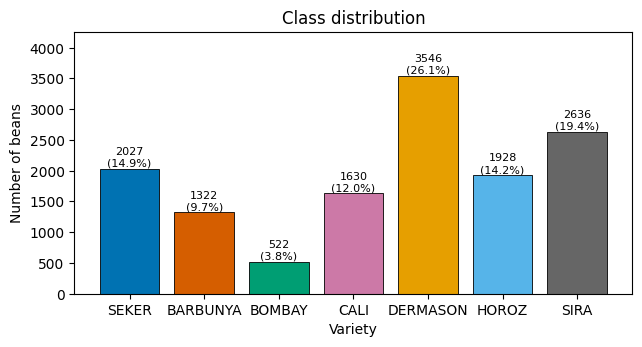

In [7]:
import matplotlib.pyplot as plt
from src.config import CLASS_ORDER, PALETTE
counts = df["Class"].value_counts().reindex(CLASS_ORDER)
fig, ax = plt.subplots(figsize=(7.2, 3.4))
ax.bar(counts.index, counts.values, color=[PALETTE[c] for c in counts.index],
       edgecolor="black", linewidth=0.6)
for i, v in enumerate(counts.values):
    ax.text(i, v + 40, f"{v}\n({100*v/counts.sum():.1f}%)", ha="center", fontsize=8)
ax.set_ylabel("Number of beans"); ax.set_xlabel("Variety")
ax.set_title("Class distribution"); ax.set_ylim(0, counts.max()*1.2)
plt.show()

## 4. Feature distributions

In [8]:
from src.eda import feature_histograms, boxplots_by_class
feature_histograms(df); boxplots_by_class(df)

  saved figures/eda/fig_3_3_feature_histograms.png


  saved figures/eda/fig_3_4_boxplots_by_class.png


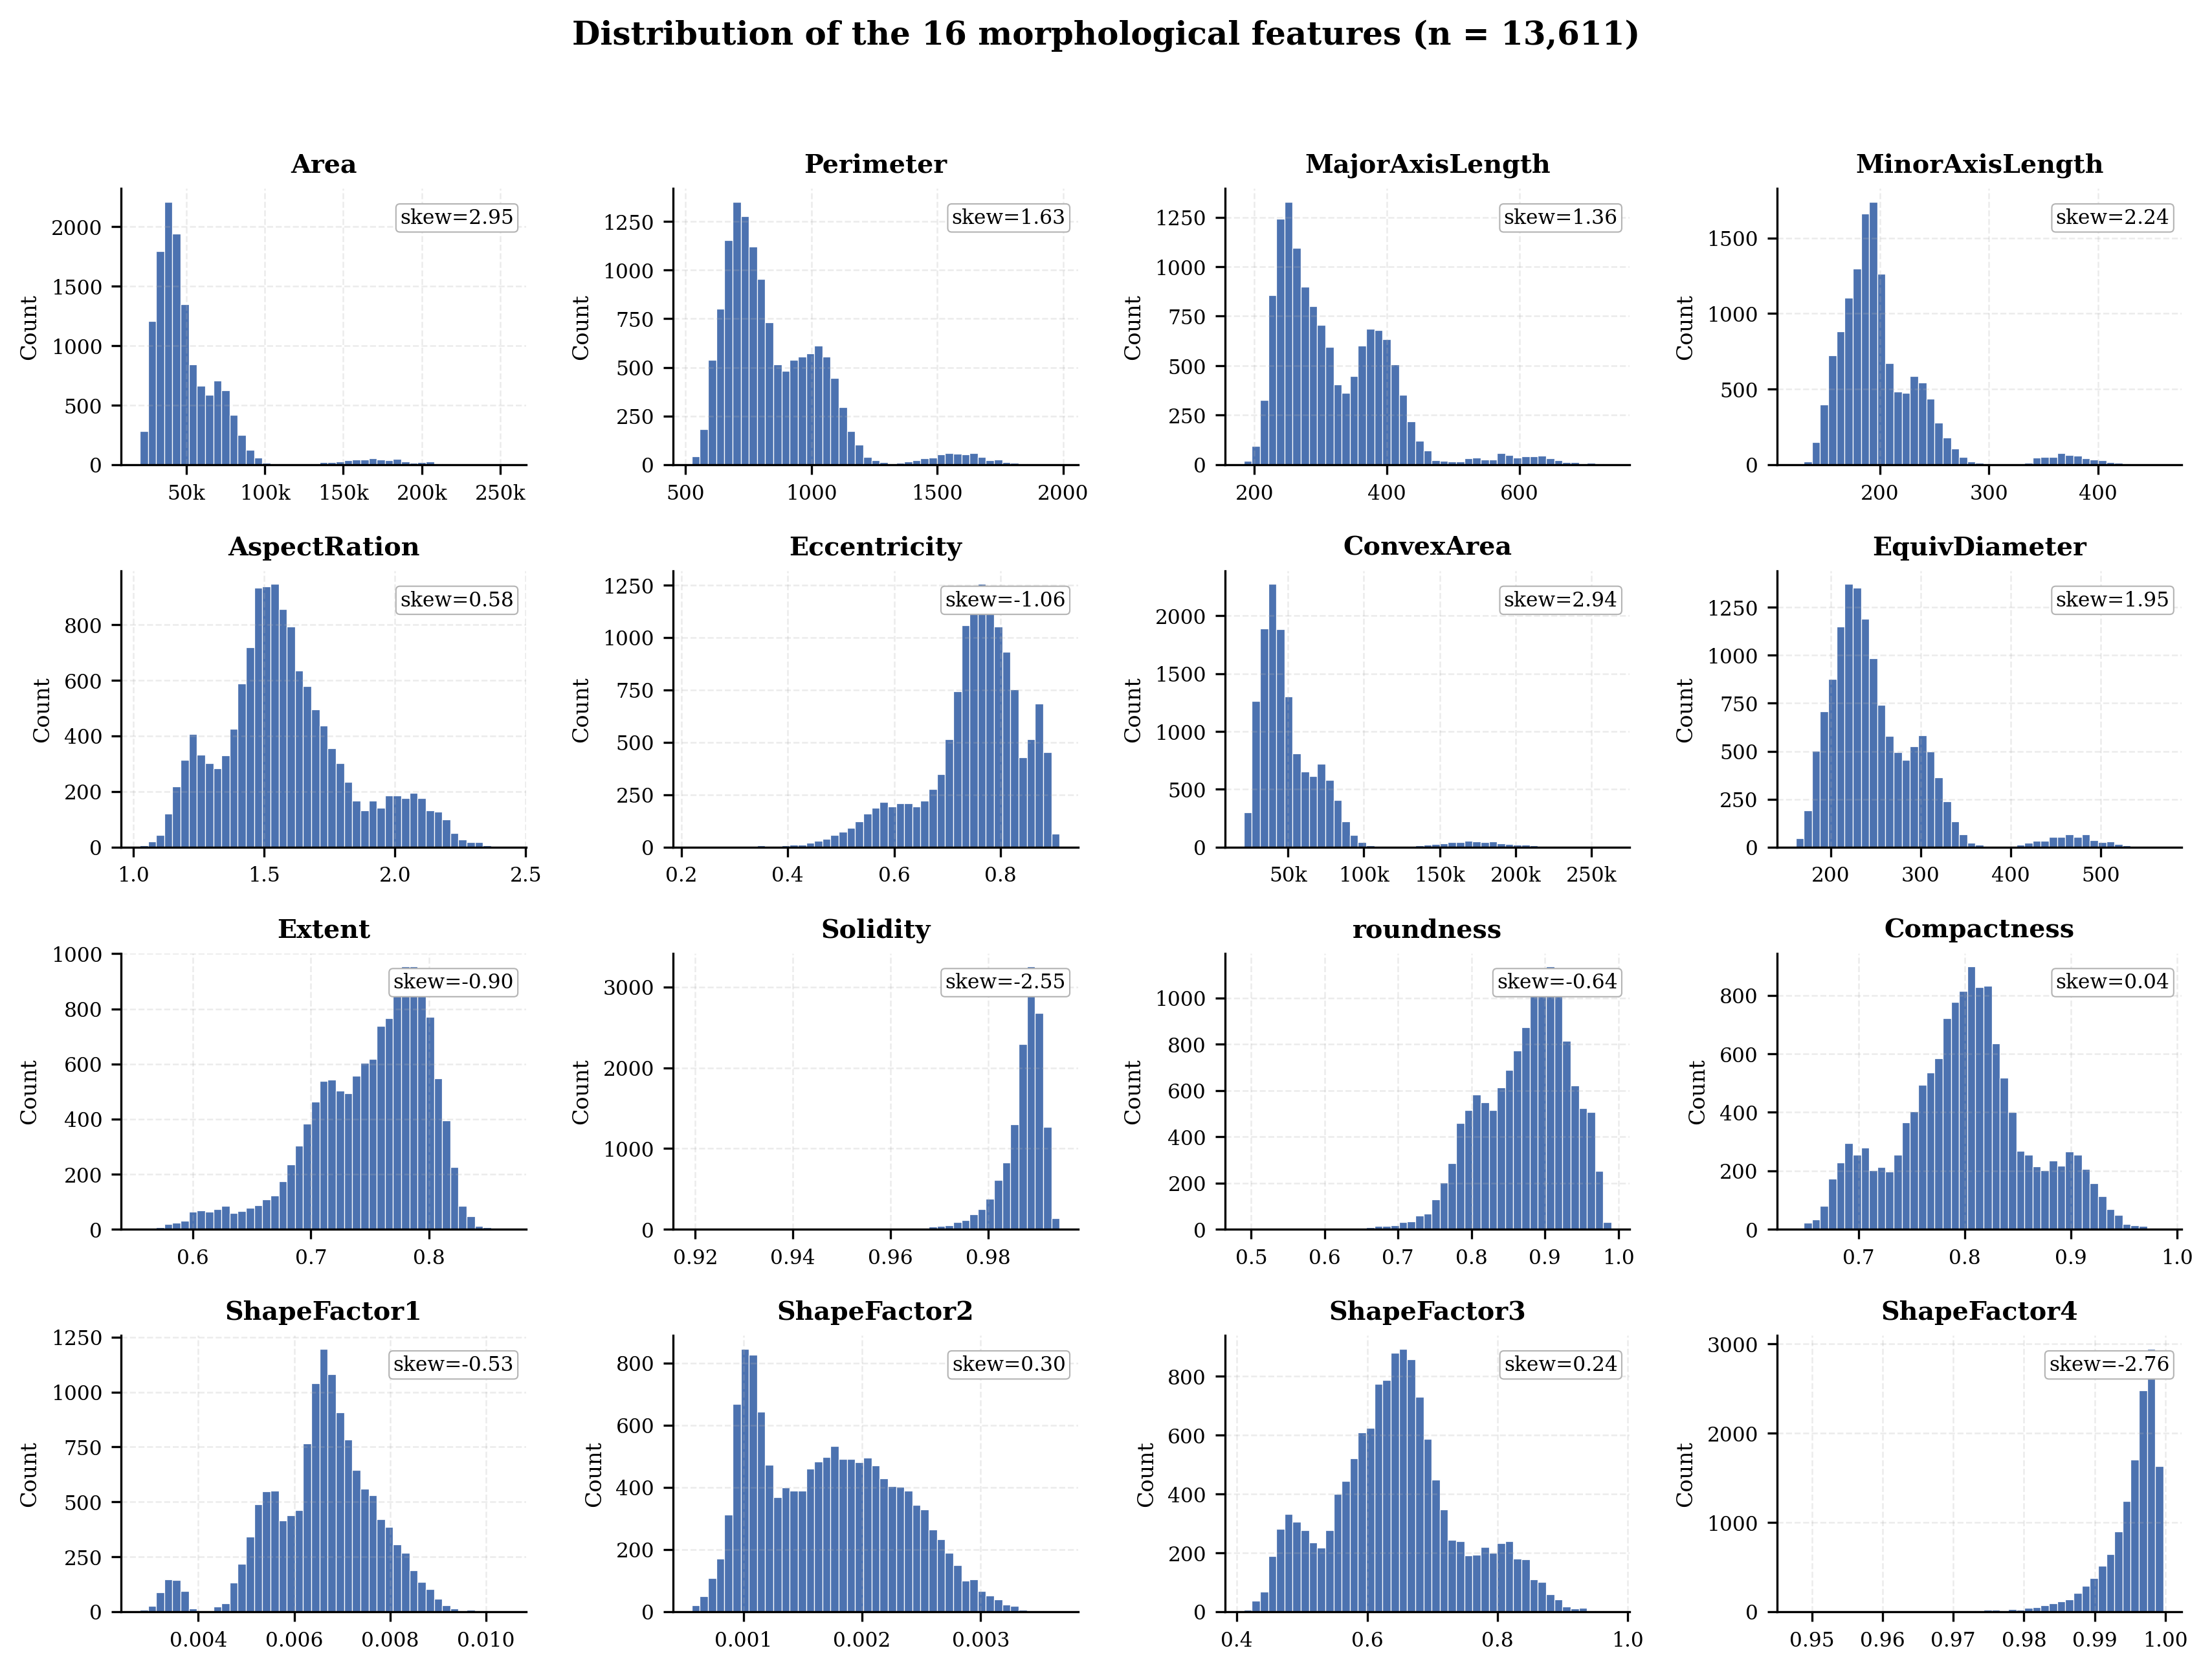

In [9]:
from IPython.display import Image, display
display(Image("figures/eda/fig_3_3_feature_histograms.png", width=980))

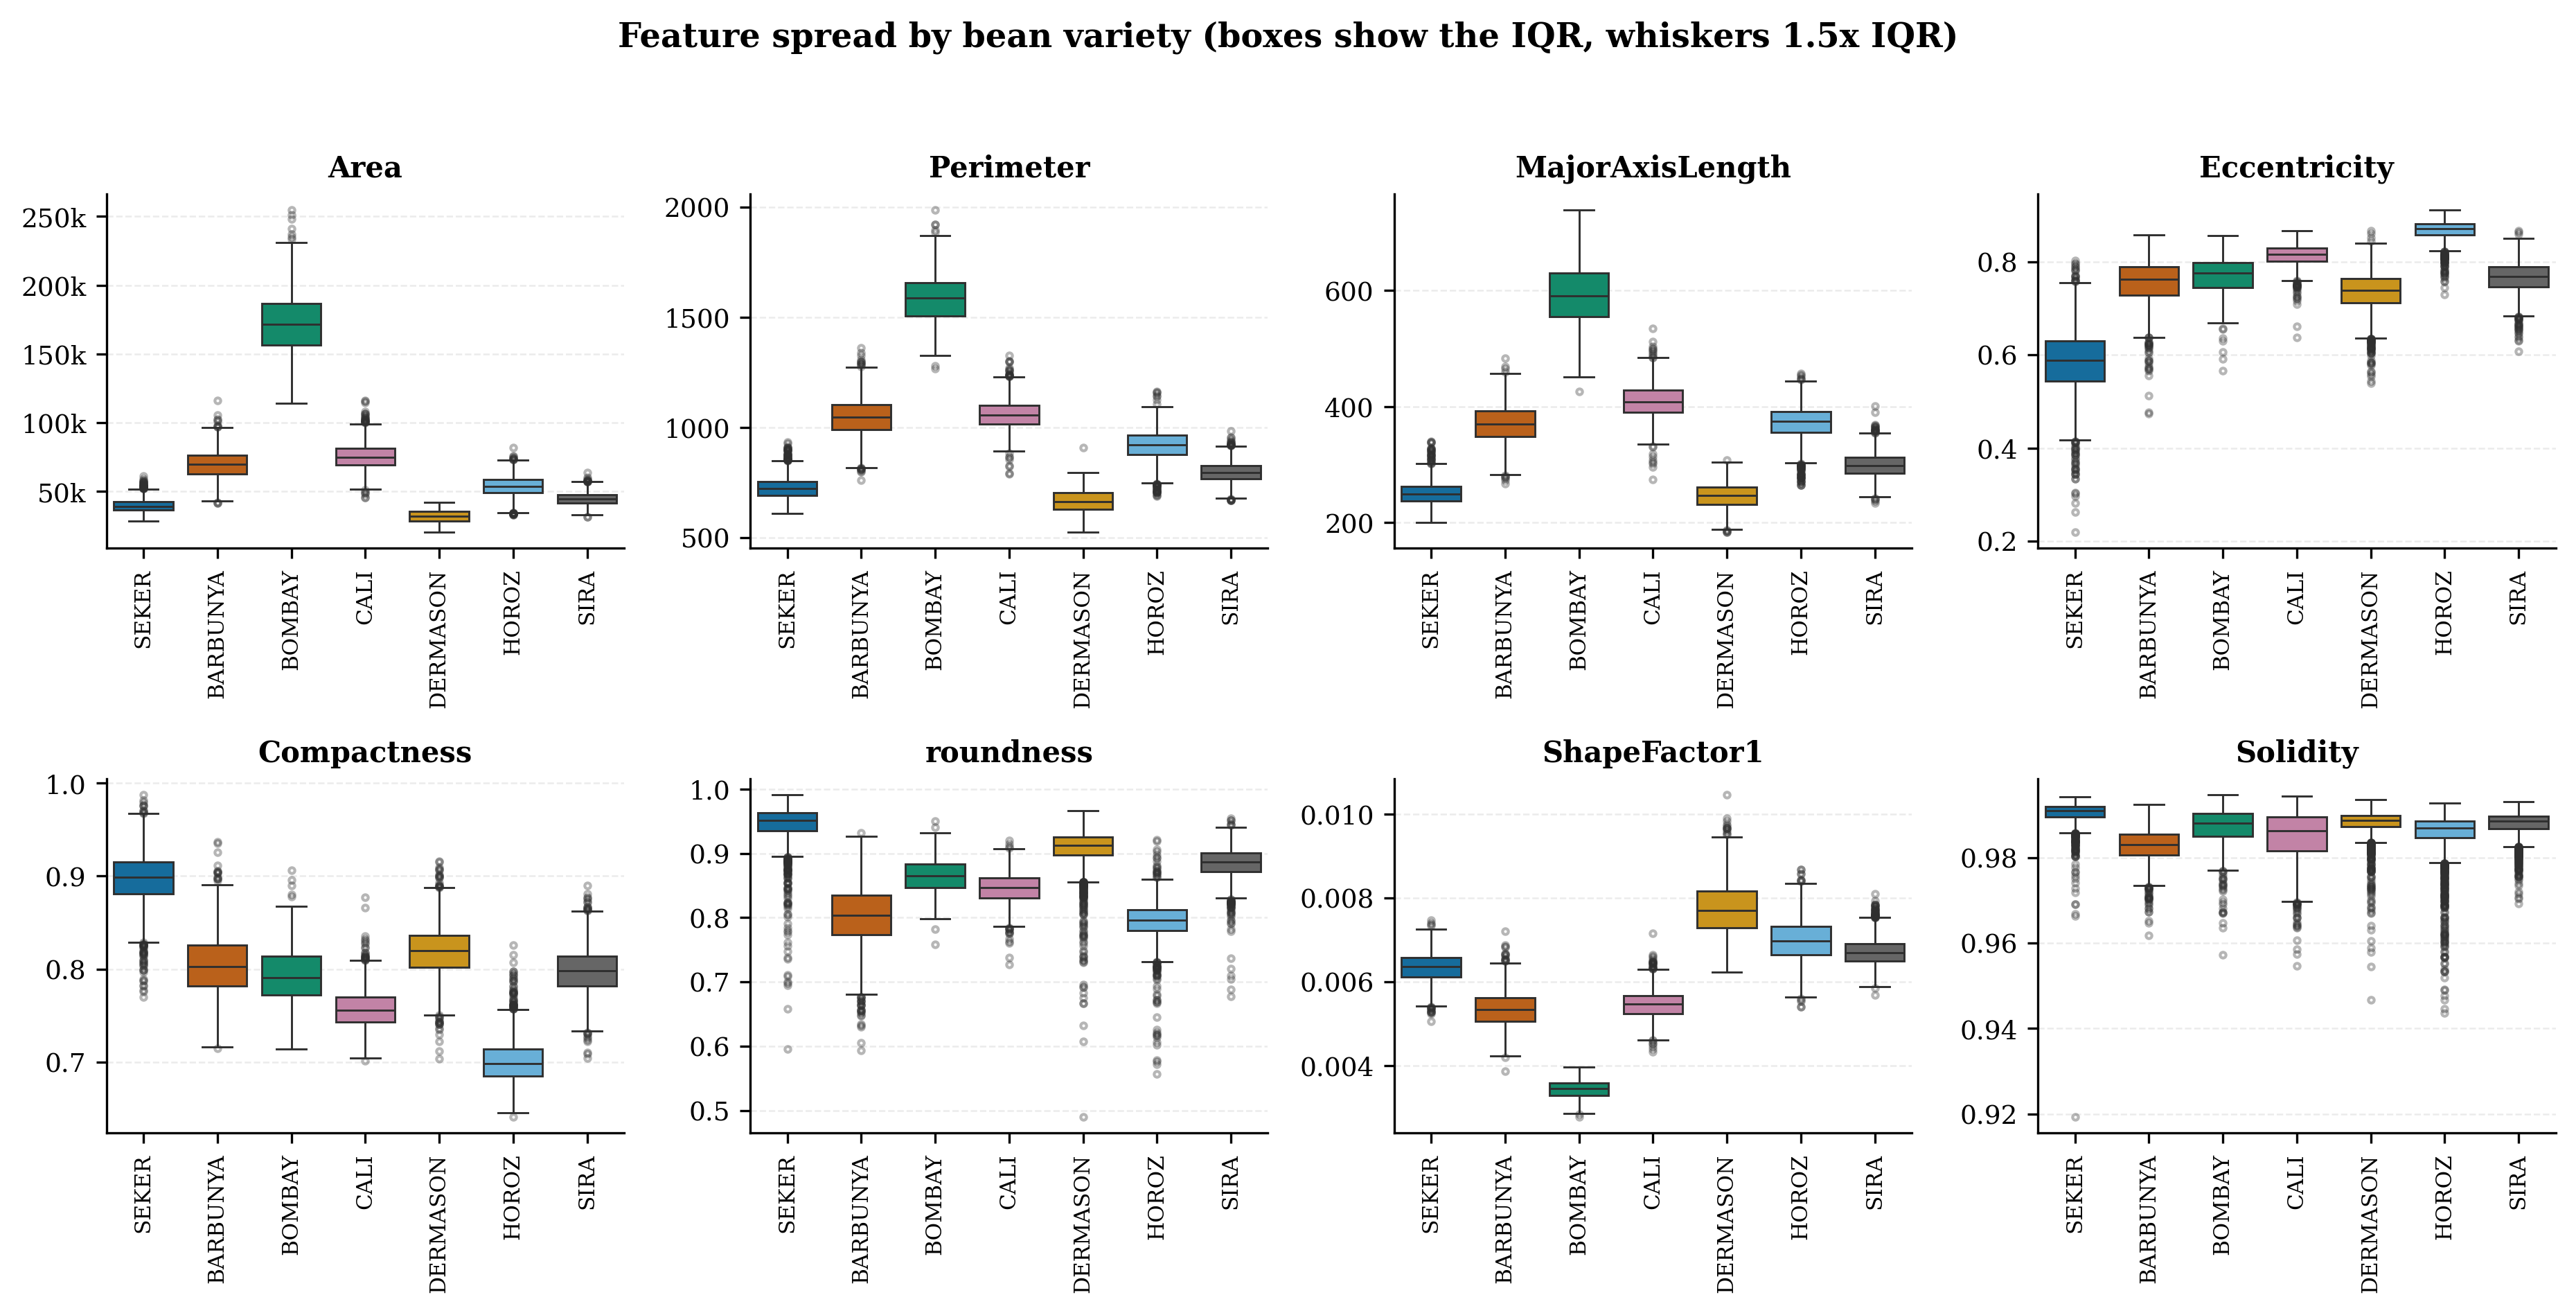

In [10]:
display(Image("figures/eda/fig_3_4_boxplots_by_class.png", width=980))

Area, perimeter, convex area and equivalent diameter are strongly
right-skewed with heavy tails, while `Solidity`, `Extent` and `ShapeFactor4` are
bounded and near-symmetric. BOMBAY sits far above the other six varieties on
every size feature, which suggests that a size axis alone will separate one
class almost perfectly while the remaining six need shape information.

## 5. Correlation structure

  saved figures/eda/fig_3_5_correlation_heatmap.png


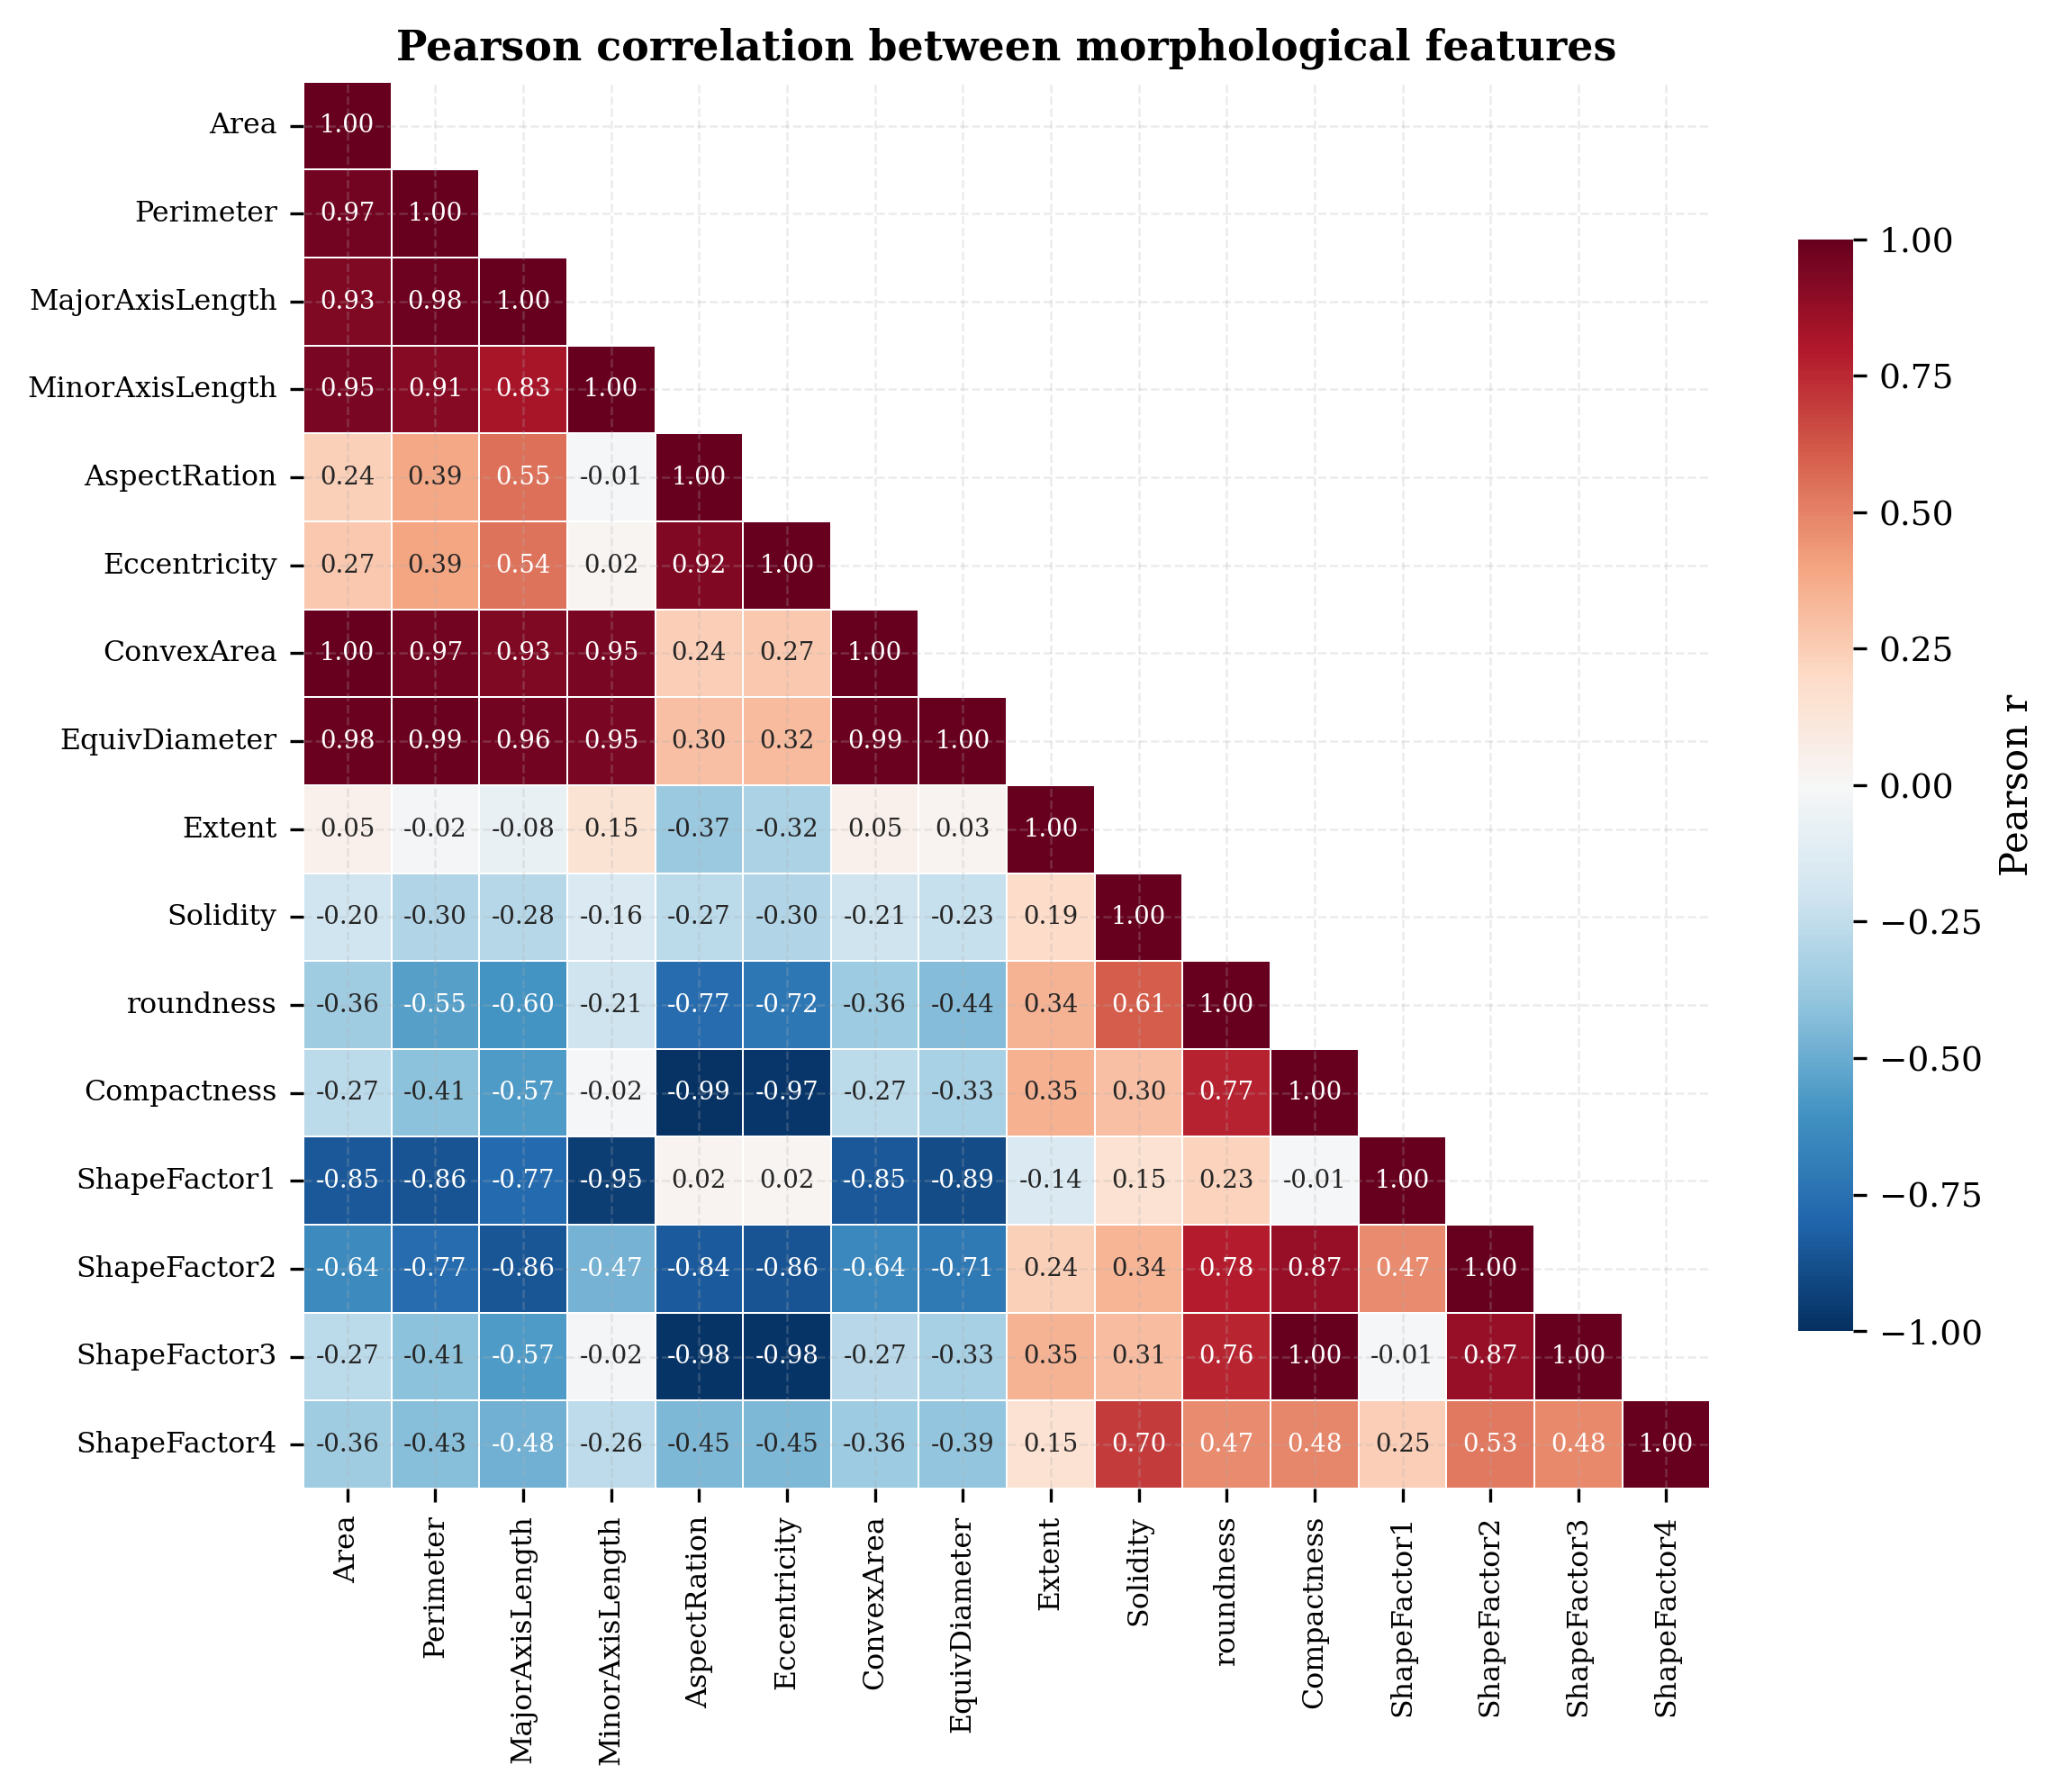

In [11]:
from src.eda import correlation_heatmap
corr = correlation_heatmap(df)
display(Image("figures/eda/fig_3_5_correlation_heatmap.png", width=720))

In [12]:
pairs = (corr.where(np.triu(np.ones(corr.shape), 1).astype(bool))
             .stack().sort_values(key=abs, ascending=False).head(12).round(3))
pairs

Area          ConvexArea         1.000
Compactness   ShapeFactor3       0.999
Perimeter     EquivDiameter      0.991
AspectRation  Compactness       -0.988
ConvexArea    EquivDiameter      0.985
Area          EquivDiameter      0.985
Eccentricity  ShapeFactor3      -0.981
AspectRation  ShapeFactor3      -0.979
Perimeter     MajorAxisLength    0.977
Eccentricity  Compactness       -0.970
Perimeter     ConvexArea         0.968
Area          Perimeter          0.967
dtype: float64

Twenty-one pairs exceed |r| = 0.90. `Area` and `ConvexArea` are almost
the same variable (r = 0.9999) because beans are nearly convex. This does not
justify deleting features: tree ensembles can exploit the small residual
difference, and Section 6.2 reports an ablation that tests the cost of dropping
the redundant size cluster.

## 6. Class-wise separation

  saved figures/eda/fig_3_7_classwise_comparison.png


  saved figures/eda/fig_3_8_scatter_relationships.png


  saved figures/eda/fig_3_6_pairplot.png


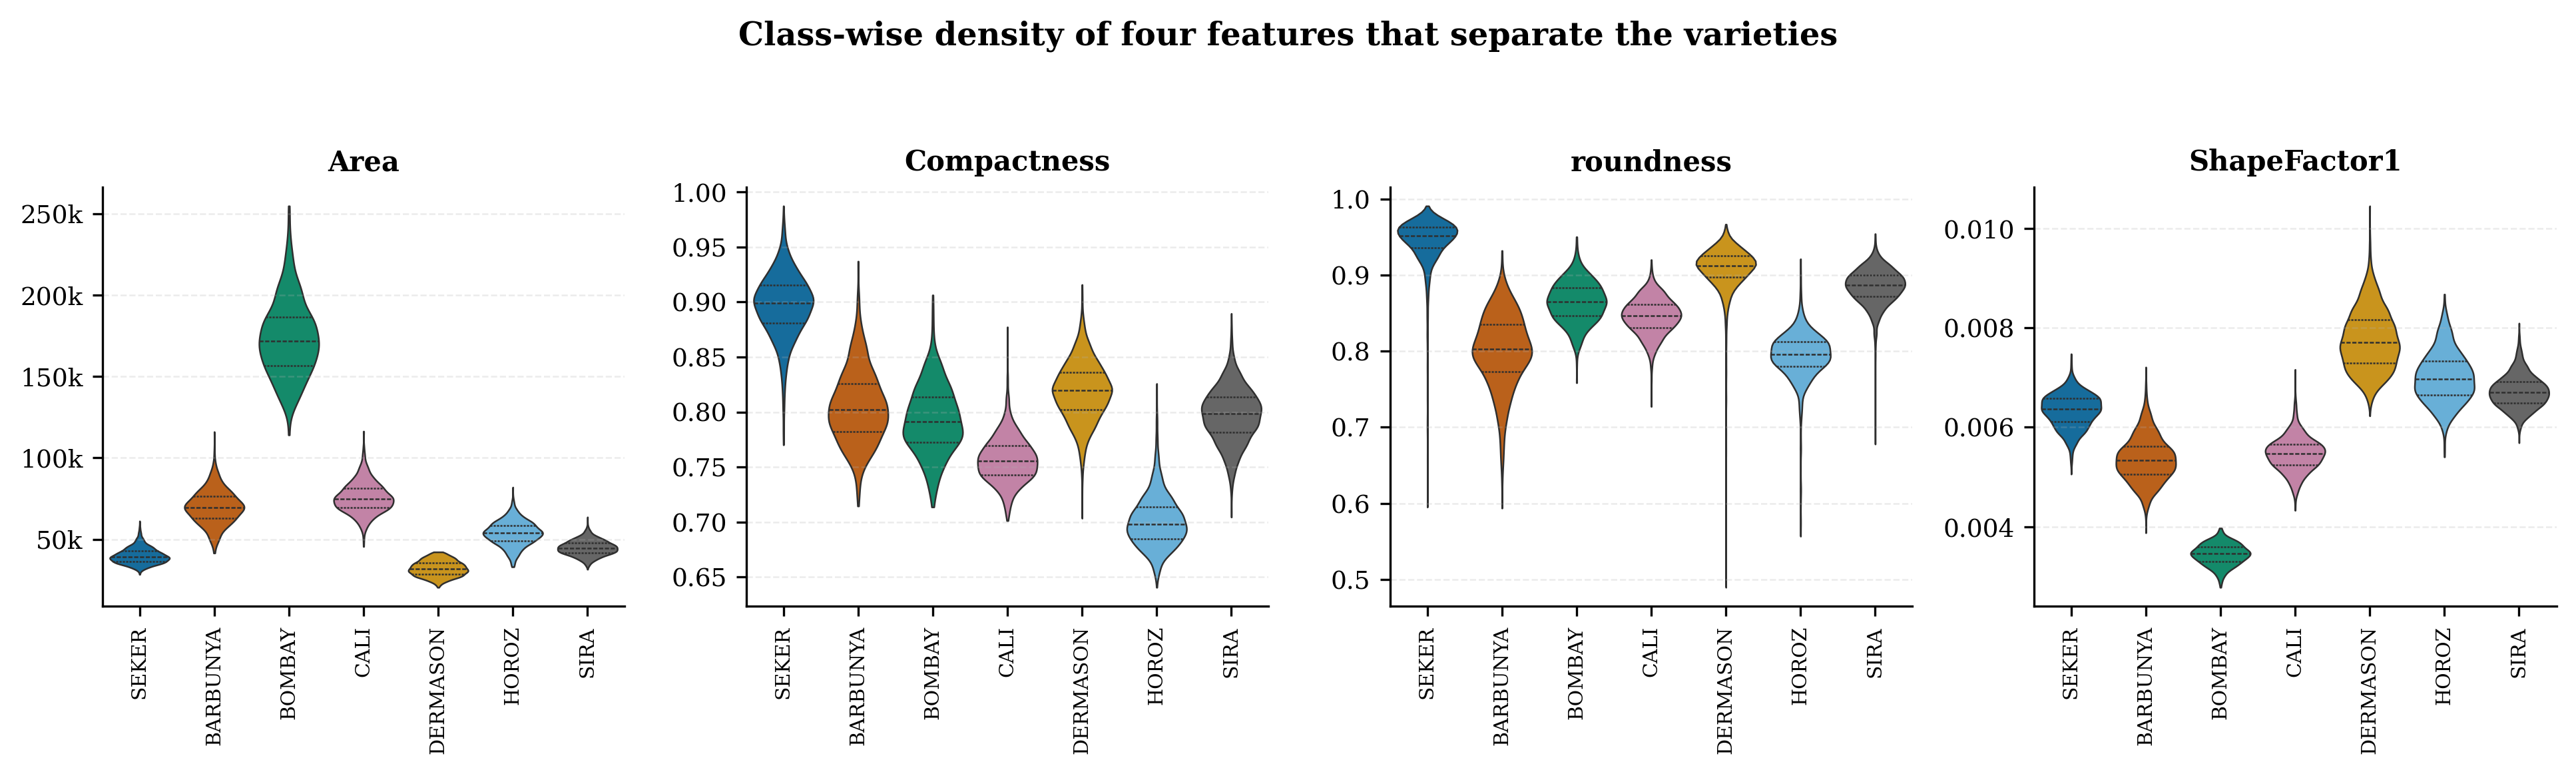

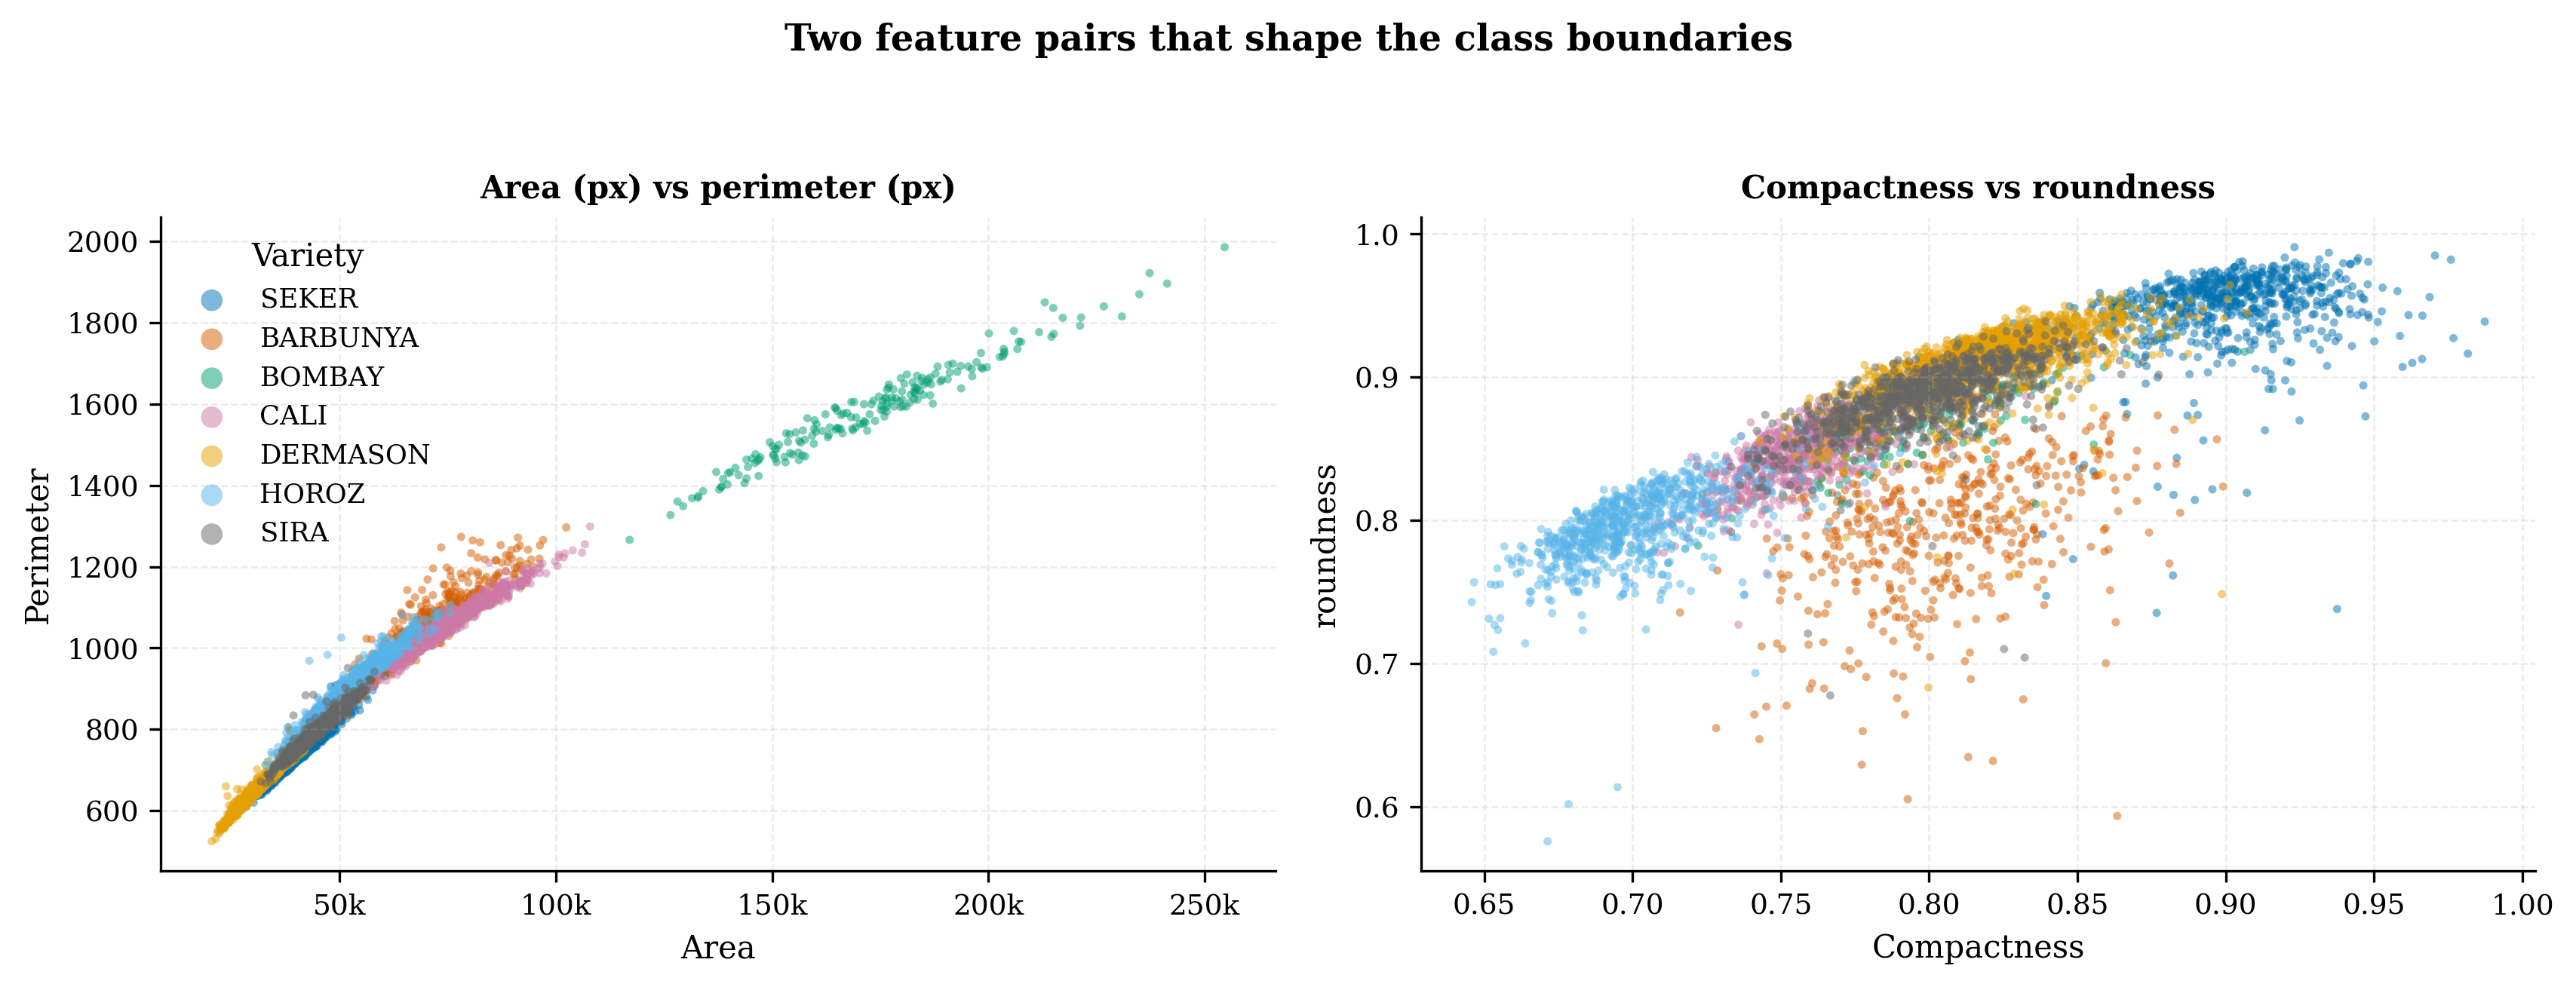

In [13]:
from src.eda import classwise_comparison, pairplot, scatter_relationships
classwise_comparison(df); scatter_relationships(df); pairplot(df)
display(Image("figures/eda/fig_3_7_classwise_comparison.png", width=1000))
display(Image("figures/eda/fig_3_8_scatter_relationships.png", width=1000))

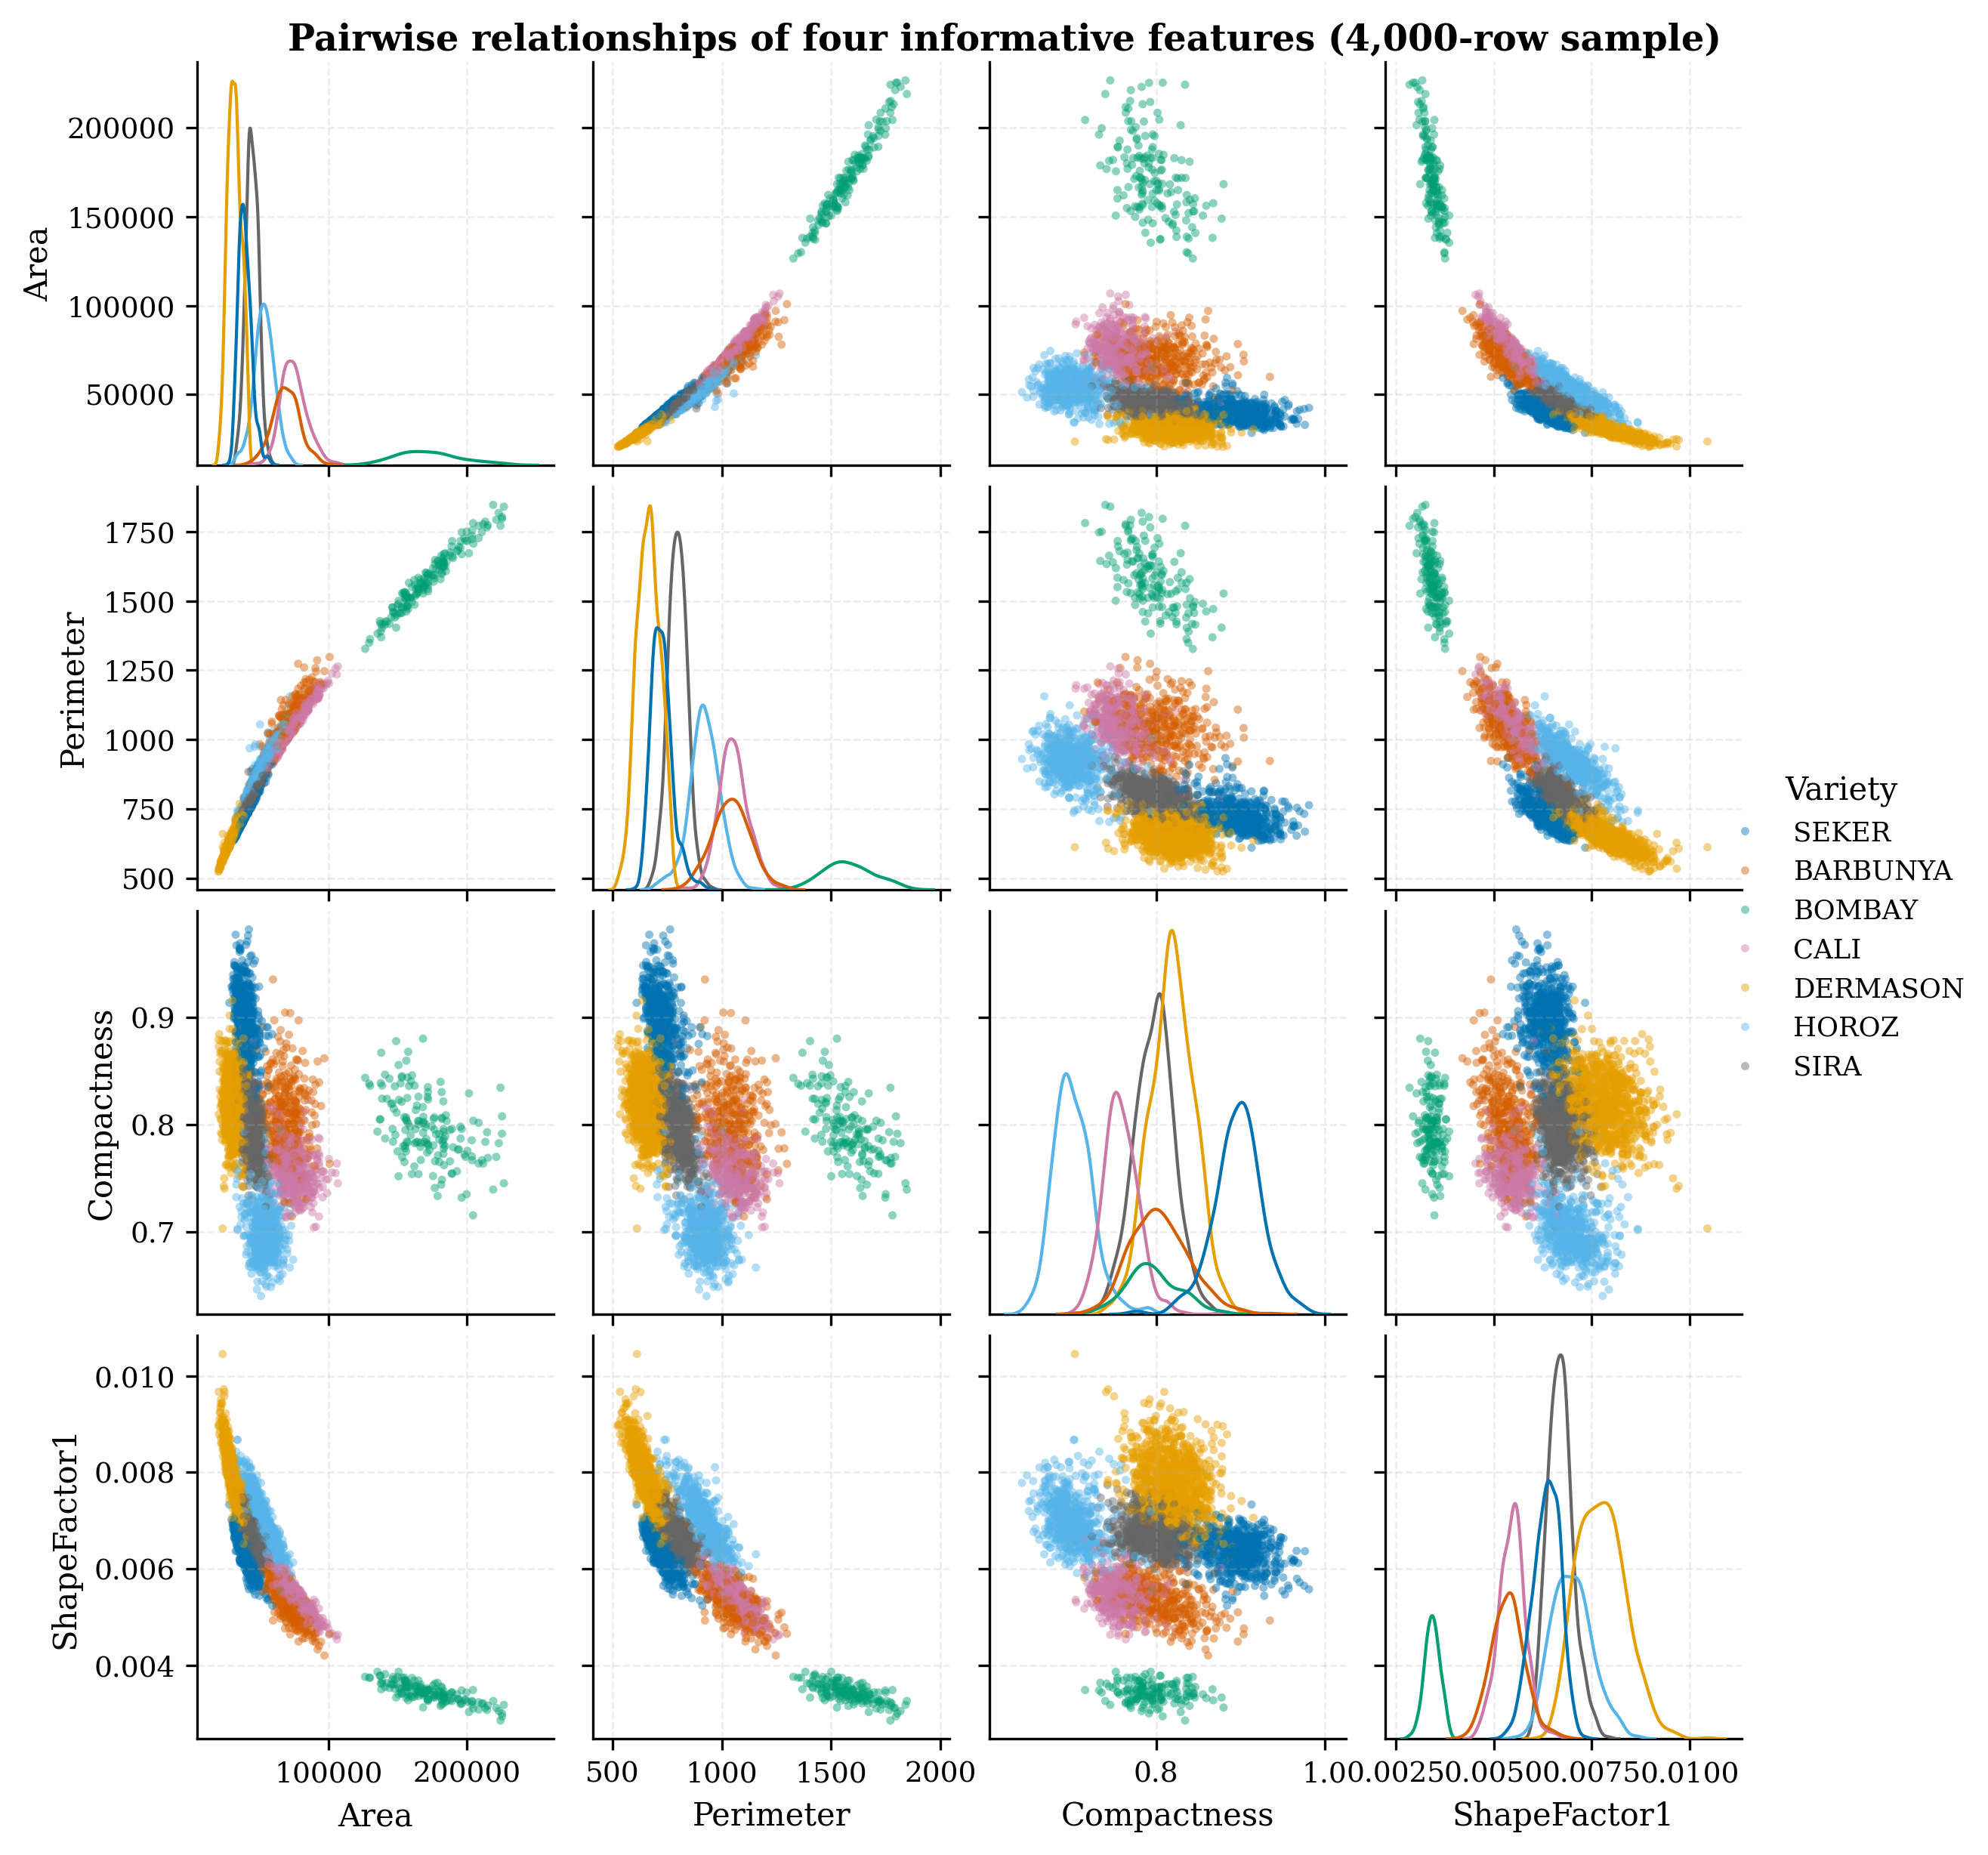

In [14]:
display(Image("figures/eda/fig_3_6_pairplot.png", width=760))

The pair plot shows two clean clusters (BOMBAY and DERMASON) and one
dense, overlapping cloud containing SEKER, BARBUNYA, CALI, HOROZ and SIRA. The
expected error rate is therefore concentrated inside that cloud, which is what
the confusion matrices in Chapter 6 confirm.

## 7. Outliers and discriminative power

  saved figures/eda/fig_3_9_outlier_analysis.png


  saved figures/eda/fig_3_10_discriminative_power.png


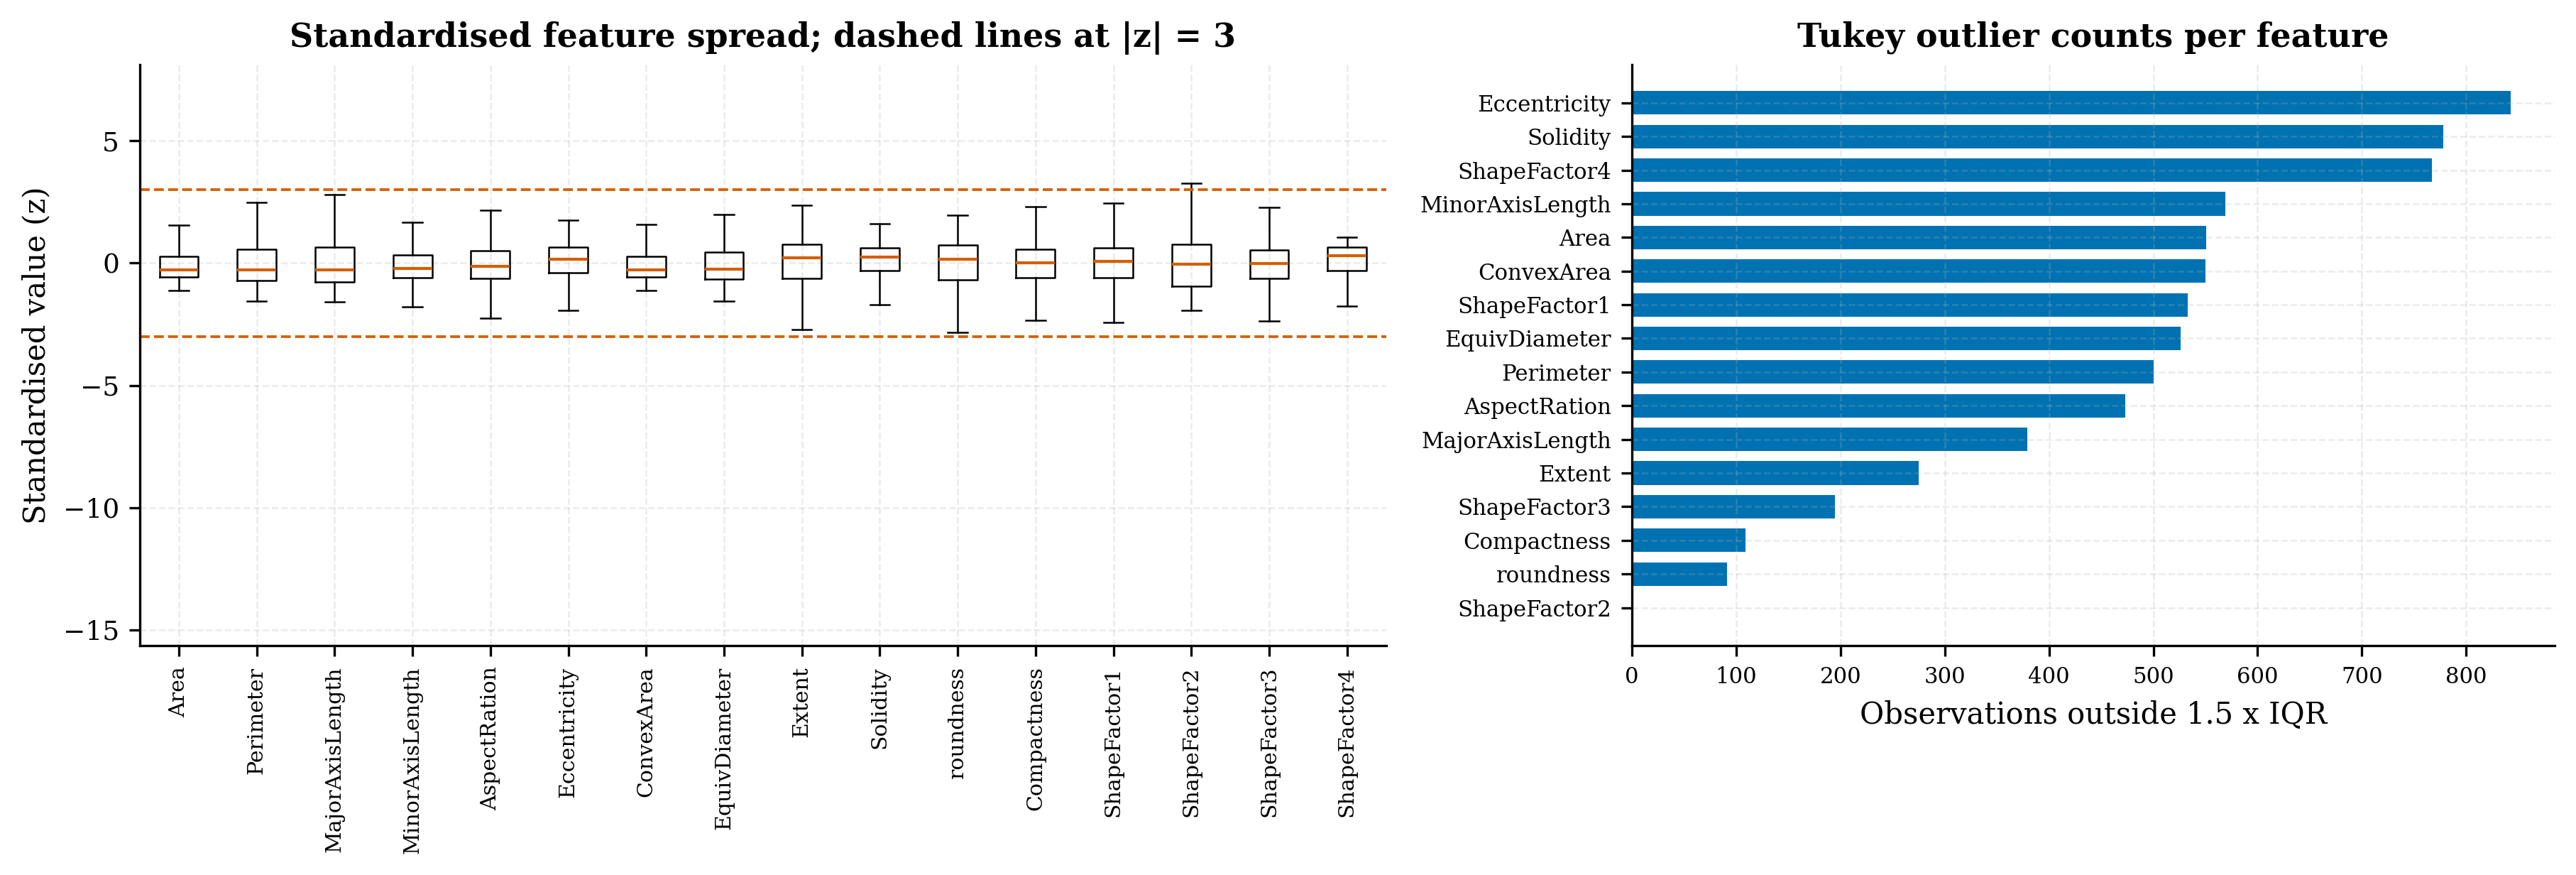

,feature,F,p_value
0,Area,29017.51,0.0
6,ConvexArea,28961.79,0.0
7,EquivDiameter,25444.55,0.0
1,Perimeter,24283.66,0.0
3,MinorAxisLength,22442.39,0.0
2,MajorAxisLength,21622.24,0.0
13,ShapeFactor2,12329.88,0.0
12,ShapeFactor1,12081.32,0.0
4,AspectRation,10376.98,0.0
11,Compactness,10166.12,0.0


In [15]:
from src.eda import outlier_analysis, discriminative_power
outlier_analysis(df)
anova = discriminative_power(df)
display(Image("figures/eda/fig_3_9_outlier_analysis.png", width=1000))
anova.head(10).round(2)

Tukey's rule flags up to 843 observations per feature, but almost all of
them are legitimate large beans from BOMBAY rather than measurement errors. No
observation was removed. `ShapeFactor1` and `Compactness` carry the largest
between-class F-statistics after the size features.

## 8. Observations carried into modelling

1. The classes are imbalanced by a factor of 6.8 (DERMASON 3,546 vs
BOMBAY 522), so macro-averaged F1 is the selection metric rather than accuracy.
2. Size features separate BOMBAY; shape features must separate the remaining six.
3. Feature magnitudes differ by four orders of magnitude, so distance- and
margin-based learners need standardisation.
4. Heavy-tailed features suggest that tree ensembles will be competitive
because they do not assume normality.
5. No missing values and no non-finite values, so imputation is unnecessary.